In [17]:
import time
import torch
import numpy as np
from addict import Dict
import matplotlib.pyplot as plt

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager

# 可视化
from utils.visualizer import plot_events_3d, plot_event_time2d, save_voxel_grid_video, plot_flow_field
from Cmax import ContrastMaximizationLoss
from methods import inr_vg,inr_est,of_vg,of_est, ilk_vg, ilk_est, affineGS, constGS, compute_flow_quantities
# 评价指标
from utils.metrics import PIVmetric
from gaussian_flow import GaussianFlowConfig, run_gaussian_flow

from Cmax import ContrastMaximizationLoss

667.98804 6.368 674.356
torch.Size([146861, 4])


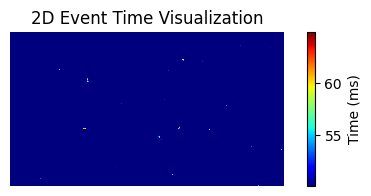

In [21]:
flow_index = 3
flow_names = ["rotation", "ebiv", "jet", "water"]

cases = [
    Dict(source_type="evk5", path="./data/real_old/rotation8.23.hdf5"), 
    Dict(source_type="real", path="./data/real_old/ebiv_wallflow4_dense.h5"),
    Dict(source_type="evk5", path="./data/real_old/starting_jet.hdf5"),
    Dict(source_type="evk5", path="./data/2-1.hdf5")
    
]

event_loader = EventManager(**cases[flow_index])
evts, _ = event_loader.load()
print(evts[:, 2].max()-evts[:, 2].min(), evts[:, 2].min(), evts[:, 2].max())

evts1 = torch.tensor(evts[(evts[:, 2] > 50) & (evts[:, 2] < 65)]).to("cuda")
# evts2 = torch.tensor(evts[(evts[:, 2] > 10) & (evts[:, 2] < 50)]).to("cuda")

print(evts1.shape)

data = np.load("./data/real_old/rotation8.23_truth.npz")
vel_h = data["u"]
vel_w = data["v"]

flowgt = torch.stack([torch.tensor(vel_h), torch.tensor(vel_w)], dim=0).to("cuda")
plot_event_time2d(evts1, output_file=None)
# plot_flow_field(u_gt, v_gt)
# plot_flow_field(vel_h, vel_w, output_file=None, v_min = 0, v_max = 3, colorbar_flag=True, step=1, quiver_step=64, 
#                 scale=None, slFlag=False, figsize=(5, 3), cbar_ticks=None, cbar_tick_size=12)
torch.cuda.empty_cache()

[AutoLR] lr_jacobian = 0.01 (manual)
开始训练 | 初始高斯数: 200
Iter 0000 | total=-6.994279 | data=-8.550137 | div=0.021446 | smooth=0.048354 | J_grad=1.19927 | N=200
  [Clone] candidates=173251  after_filter=48
total_triggered=5  
  [Prune] opacity_mean=0.287  geometry=14  total=74
  [{'split', 'prune', 'clone'}] Clone:48  Split:5  Prune:74  -> N=179
Iter 0050 | total=-12.826559 | data=-13.577347 | div=0.010720 | smooth=0.021480 | J_grad=76.69202 | N=179
  [Clone] candidates=173251  after_filter=44
total_triggered=14  
  [Prune] opacity_mean=0.333  geometry=16  total=96
  [{'split', 'prune', 'clone'}] Clone:44  Split:14  Prune:96  -> N=141
Iter 0100 | total=-19.246321 | data=-19.816917 | div=0.008866 | smooth=0.012731 | J_grad=140.58681 | N=141
  [Clone] candidates=173251  after_filter=43
total_triggered=13  
  [Prune] opacity_mean=0.507  geometry=15  total=52
  [{'split', 'prune', 'clone'}] Clone:43  Split:13  Prune:52  -> N=145
Iter 0150 | total=-23.620094 | data=-23.849926 | div=0.004041 | 

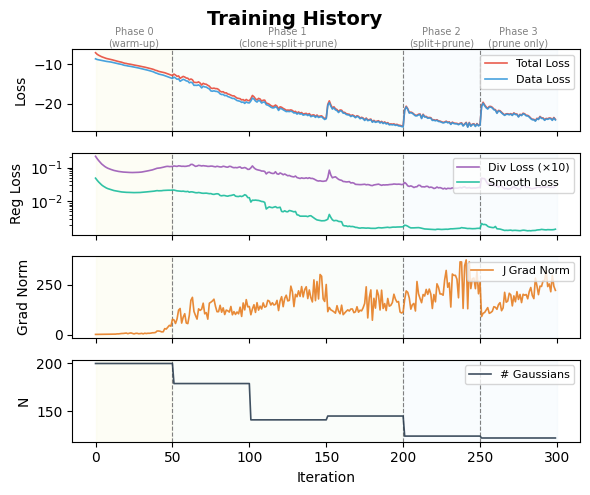

验证推理中（训练分辨率 720×1280 → 输出分辨率 720×1280）...
验证推理完成
运行时间: 6.913046 秒


In [6]:
start = time.time()
cfg = GaussianFlowConfig(H=720, W = 1280, init_n=200, w_div=50, verbose=True, tile_size=80, 
                         w_smooth = 10, cmax_sigma= 0.6, cmax_kernel_size = 5, lr_j=0.01)
results = run_gaussian_flow(events=evts1, cfg=cfg, flowgt=None)

end = time.time()     # 记录结束时间
print(f"运行时间: {end - start:.6f} 秒")
torch.cuda.empty_cache()

In [7]:
div = results.div
omega = results.vorticity
res = PIVmetric(vel_h, vel_w, results.flow[0], results.flow[1], show=True)

3.6557(RMSE)	3.4353(AEE)	2.1022(AAE,rad)	-0.1509(SSIM)	-0.7426(MoC)	906677(epe1)	770325(epe2)	589107(epe3)	


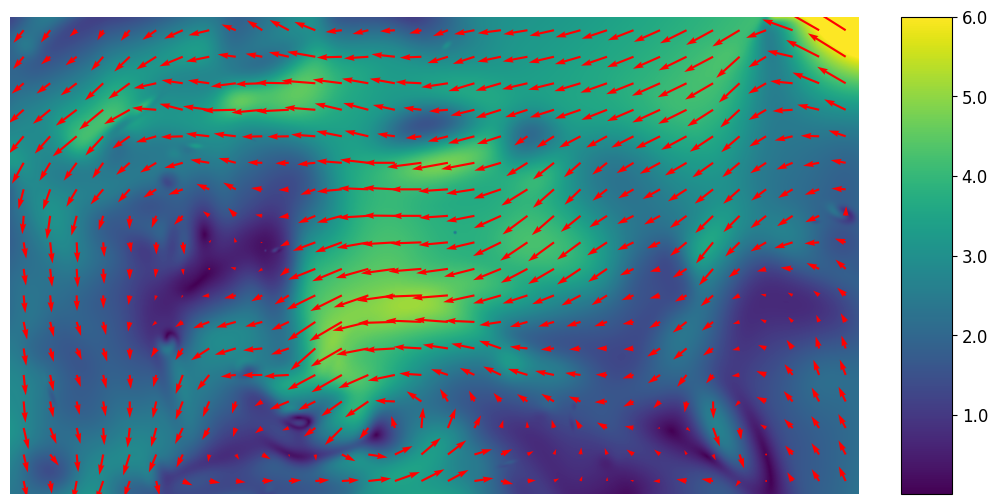

In [8]:
plot_flow_field(results.flow[0], results.flow[1], output_file=None, v_max = 6, 
                colorbar_flag=True, step=1, quiver_step=40, scale=None, slFlag=False, figsize=(10, 6))

Calculated Loss: -23.7811


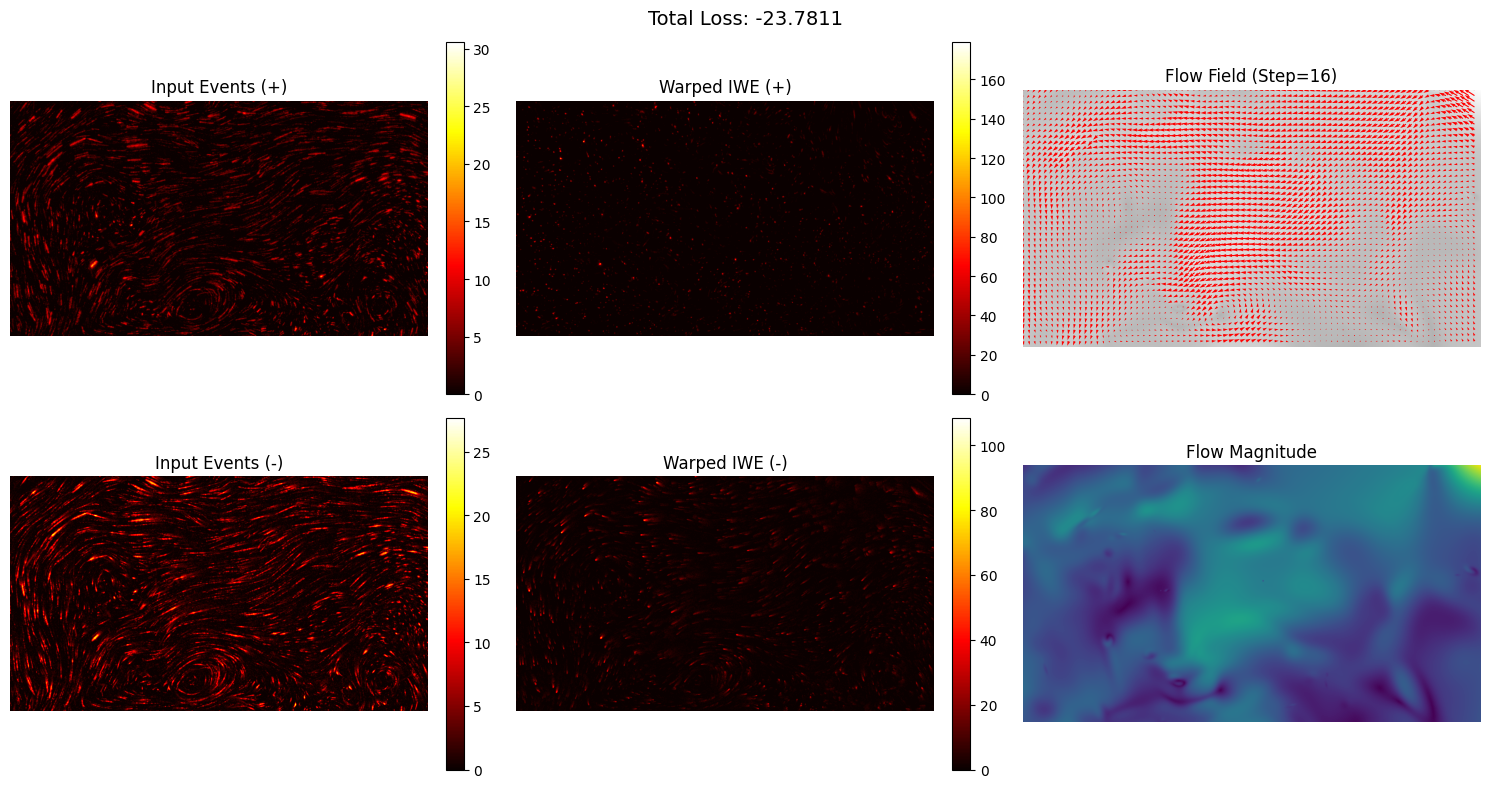

In [16]:
cmax_loss = ContrastMaximizationLoss(loss_type='l2_max', sigma=0.6, kernel_size=5).to("cuda")  # variance, l2_max, structure
loss = cmax_loss(evts1, torch.tensor(results.flow).to("cuda"), (720, 1280), vis=True)
print(f"Calculated Loss: {loss.item():.4f}")
# --- 可视化 ---
cmax_loss.plot_visualization(grid_step=16, grid_loss_n=None)

In [ ]:
estimators = [ilk_vg, of_vg, inr_est, inr_vg]
method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG"]

# estimators = [inr_vg]
# method_names = ["INR_VG"]

def test(events, H=256, W=256):
    for i, m in enumerate(estimators):
        v_h, v_w, div, vor = m(events, H=H, W=W)
        plot_flow_field(v_h, v_w, None, None, output_file=None, magFlag=True, slFlag=False, colorbar_flag=True, step=1, quiver_step=40, 
                            v_min=0, v_max=5, scale=None, figsize=(5, 3), cbar_ticks=None, cbar_tick_size=12)
        torch.cuda.empty_cache()

In [ ]:
v_h, v_w = test(evts1, H=720, W=1280)